# `awe-agent-function` — tutorial

Five steps to make a Python package agent-friendly:

1. Install the package: `pip install -e .` (from the repo root).
2. Decorate one function by hand and inspect the registry.
3. Auto-decorate a foreign package (sklearn) without modifying its source.
4. Audit the resulting registry against the AFS rubric.
5. Visualise the AFS distribution and compare omicverse vs sklearn.

All output cells below were generated by re-executing the
notebook end-to-end.

## Step 1 · Decorate by hand

The decorator is the only authoring surface. Everything else
(registry, lookup, AFS audit) is derived from what you wrote
at the call site.

In [1]:
import warnings
warnings.filterwarnings('ignore')
from awe_agent_function import register_function, registry_lookup, registry_summary

@register_function(
    aliases=['zscore', 'standard score', 'z-score', '标准化'],
    category='preprocessing',
    description='Convert a 1-D numeric array to its z-score (zero mean, unit variance).',
    requires={'shape': ['1d_array']},
    produces={'shape': ['1d_array'], 'metrics': ['mean=0', 'std=1']},
    examples=['zscore([1, 2, 3, 4, 5])  # array([-1.41, -0.71, 0.0, 0.71, 1.41])'],
    related=['minmax_scale', 'robust_scale'],
)
def zscore(x):
    import numpy as np
    x = np.asarray(x, dtype=float)
    sd = x.std(ddof=0)
    return (x - x.mean()) / (sd if sd else 1.0)

print(registry_lookup('z-score'))

Found 1 matching function(s) for 'z-score':

[1] __main__.zscore
    desc:      Convert a 1-D numeric array to its z-score (zero mean, unit variance).
    aliases:   zscore, standard score, z-score, 标准化
    category:  preprocessing
    signature: (x)
    examples:
       zscore([1, 2, 3, 4, 5])  # array([-1.41, -0.71, 0.0, 0.71, 1.41])
    related:   minmax_scale, robust_scale
    requires:  shape:1d_array
    produces:  shape:1d_array, metrics:mean=0, metrics:std=1


## Step 2 · Auto-decorate sklearn (no source mod)

The same registry surface, applied to a package the framework
authors do not own. `auto_decorate` walks sklearn's public API,
AST-extracts each callable's signature + docstring, and
synthesises a registry entry per public function / class.

In [2]:
from awe_agent_function import auto_decorate
n = auto_decorate('sklearn', recurse_depth=2)
print(f'registered {n} sklearn entries')

registered 544 sklearn entries


## Step 3 · Natural-language lookup

The agent (or you) queries the registry with a phrase that
describes the analytical decision, not the function name. The
lookup returns full name, AST-derived signature, examples, and
the 'See Also' list for further navigation.

In [3]:
for q in [
    'random forest classifier',
    'feature selection wrapper',
    'silhouette score for clustering',
    'stratified k-fold cross validation',
]:
    print('=' * 72)
    print(f'registry_lookup({q!r}):')
    print('=' * 72)
    print(registry_lookup(q, max_results=2))
    print()

registry_lookup('random forest classifier'):
Found 2 matching function(s) for 'random forest classifier':

[1] sklearn.ensemble._forest.RandomTreesEmbedding
    desc:      An ensemble of totally random trees.
    aliases:   random, trees, embedding, RandomTreesEmbedding, ensemble RandomTreesEmbedding, ExtraTreesClassifier, ExtraTreesRegressor, RandomForestClassifier
    category:  sklearn.ensemble
    signature: (n_estimators=100, *, max_depth=5, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_leaf_nodes=None, min_impurity_decrease=0.0, sparse_output=True, n_jobs=None, random_state=None, verbose=0, warm_start=False)
    examples:
       from sklearn.ensemble import RandomTreesEmbedding
       X = [[0,0], [1,0], [0,1], [-1,0], [0,-1]]
    related:   ExtraTreesClassifier, ExtraTreesRegressor, RandomForestClassifier, RandomForestRegressor, sklearn.tree.ExtraTreeClassifier

[2] sklearn.ensemble._forest.RandomForestClassifier
    desc:      A random forest classif

Found 1 matching function(s) for 'silhouette score for clustering':

[1] sklearn.metrics.cluster._unsupervised.silhouette_score
    desc:      Compute the mean Silhouette Coefficient of all samples.
    aliases:   silhouette, score, silhouette_score, cluster silhouette_score
    category:  sklearn.metrics
    signature: (X, labels, *, metric='euclidean', sample_size=None, random_state=None, **kwds)
    examples:
       from sklearn.datasets import make_blobs
       from sklearn.cluster import KMeans

registry_lookup('stratified k-fold cross validation'):
Found 2 matching function(s) for 'stratified k-fold cross validation':

[1] sklearn.model_selection._split.StratifiedKFold
    desc:      Class-wise stratified K-Fold cross-validator.
    aliases:   stratified, k, fold, StratifiedKFold, model_selection StratifiedKFold, RepeatedStratifiedKFold
    category:  sklearn.model_selection
    signature: (n_splits=5, *, shuffle=False, random_state=None)
    examples:
       import numpy as np
 

## Step 4 · AFS audit

Quantitatively grade the library against the four-dimension
rubric (Discoverability, Contract, Signature, Behaviour).
The summary tells you the library-level score and the per-
component means; the per-row table tells you which functions
to enrich next.

In [4]:
from awe_agent_function import compute_afs
rep = compute_afs(library_name='sklearn')
print(rep.summary())

Library: sklearn
  n_functions:    544
  AFS (mean):     0.520
  AFS (median):   0.550
  AFS [p10, p90]: [0.375, 0.650]
  Sub-scores (means):
    D (discoverability): 0.920  (w=0.3)
    C (contract):        0.000  (w=0.35)
    S (signature):       0.636  (w=0.15)
    B (behavioural):     0.743  (w=0.2)


## Step 5 · Visualise the AFS distribution

The histogram shows the per-function score distribution; the
bar chart shows where in the rubric the library has the most
headroom. For sklearn the contract dimension is at zero by
construction — `requires` / `produces` cannot be synthesised
from a docstring alone, only authored. That is the difference
between auto-decoration (cheap, library-agnostic, partial)
and call-site decoration (one-time author cost, full A3F).

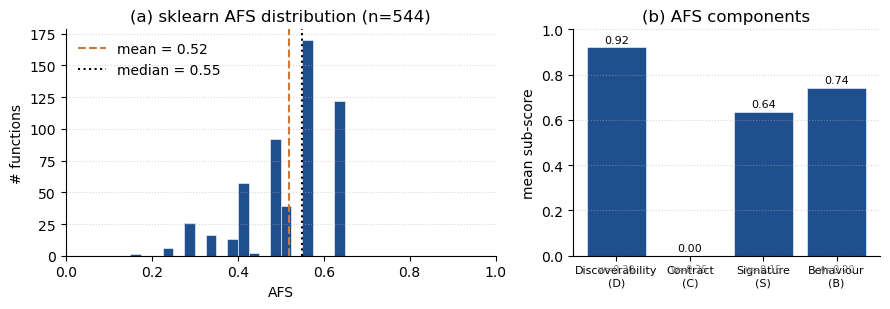

In [5]:
import matplotlib.pyplot as plt
import numpy as np

afs_vals = [r['AFS'] for r in rep.rows]
ss = rep.subscore_means
weights = rep.weights

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2),
                                gridspec_kw={'width_ratios': [1.4, 1.0]})
ax1.hist(afs_vals, bins=20, color='#1f4f8c', edgecolor='white', linewidth=0.4)
ax1.axvline(rep.library_afs_mean, color='#cc7a3a', linestyle='--',
            label=f'mean = {rep.library_afs_mean:.2f}')
ax1.axvline(rep.library_afs_median, color='black', linestyle=':',
            label=f'median = {rep.library_afs_median:.2f}')
ax1.set_xlabel('AFS')
ax1.set_ylabel('# functions')
ax1.set_xlim(0, 1)
ax1.legend(loc='upper left', frameon=False)
ax1.set_title(f'(a) sklearn AFS distribution (n={rep.n_functions})')
ax1.grid(axis='y', linestyle=':', alpha=0.5)
for sp in ('top','right'): ax1.spines[sp].set_visible(False)

labels = ['Discoverability\n(D)', 'Contract\n(C)', 'Signature\n(S)', 'Behaviour\n(B)']
vals = [ss['D'], ss['C'], ss['S'], ss['B']]
ws = [weights['D'], weights['C'], weights['S'], weights['B']]
x = np.arange(len(labels))
ax2.bar(x, vals, color='#1f4f8c', edgecolor='white', linewidth=0.4)
for xi, v in enumerate(vals):
    ax2.text(xi, v + 0.02, f'{v:.2f}', ha='center', fontsize=8)
for xi, w in enumerate(ws):
    ax2.text(xi, -0.07, f'w={w:.2f}', ha='center', fontsize=7,
             color='gray', transform=ax2.get_xaxis_transform())
ax2.set_xticks(x); ax2.set_xticklabels(labels, fontsize=8)
ax2.set_ylim(0, 1.0)
ax2.set_ylabel('mean sub-score')
ax2.set_title('(b) AFS components')
ax2.grid(axis='y', linestyle=':', alpha=0.5)
for sp in ('top','right'): ax2.spines[sp].set_visible(False)

fig.tight_layout()
plt.show()

## What's next

- Drop `awe-agent-function` into your own library and add
  `@register_function` at each public-API call site (≈ 4–5
  declarative lines per function).
- Run `compute_afs(library_name='your_pkg')` and prioritise
  the lowest-scoring entries.
- For multi-step recipes, ship Markdown skills under
  `.claude/skills/<slug>/SKILL.md`. The 12-principle content
  contract and 9-dimension rubric are at
  https://github.com/aristoteleo/awesome-skill-generate .